In [1021]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

In [1022]:
df = pd.read_csv('Telco-Customer-Churn.csv')
df.sample(5)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
3124,3889-VWBID,Male,0,Yes,Yes,68,Yes,No,DSL,Yes,...,No,Yes,Yes,Yes,Two year,No,Bank transfer (automatic),82.85,5776.45,No
3279,6064-PUPMC,Male,0,Yes,Yes,23,Yes,No,DSL,Yes,...,No,Yes,No,No,One year,No,Credit card (automatic),57.20,1423.35,No
3787,2386-OWURY,Female,0,No,No,58,Yes,No,Fiber optic,No,...,No,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,95.30,5817.7,No
5764,0716-BQNDX,Male,1,No,No,57,Yes,Yes,Fiber optic,Yes,...,No,Yes,No,Yes,Two year,No,Electronic check,93.75,5625.55,No
6976,5130-YPIRV,Female,0,Yes,No,62,Yes,No,DSL,Yes,...,Yes,No,Yes,No,Two year,Yes,Credit card (automatic),72.00,4284.2,No


In [1023]:
df.sample(5)
df = df.drop(columns = 'customerID')

In [1024]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'],errors = 'coerce')
print(df[df['TotalCharges'].isnull()]['tenure'])
df['TotalCharges'] = df['TotalCharges'].fillna(0)


488     0
753     0
936     0
1082    0
1340    0
3331    0
3826    0
4380    0
5218    0
6670    0
6754    0
Name: tenure, dtype: int64


In [1025]:
df.shape

(7043, 20)

In [1026]:
df.dtypes

gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges        float64
Churn                   str
dtype: object

In [1027]:
for x in df.columns:
    if df[x].dtypes == 'str':
        print(df[x].value_counts())

gender
Male      3555
Female    3488
Name: count, dtype: int64
Partner
No     3641
Yes    3402
Name: count, dtype: int64
Dependents
No     4933
Yes    2110
Name: count, dtype: int64
PhoneService
Yes    6361
No      682
Name: count, dtype: int64
MultipleLines
No                  3390
Yes                 2971
No phone service     682
Name: count, dtype: int64
InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64
OnlineSecurity
No                     3498
Yes                    2019
No internet service    1526
Name: count, dtype: int64
OnlineBackup
No                     3088
Yes                    2429
No internet service    1526
Name: count, dtype: int64
DeviceProtection
No                     3095
Yes                    2422
No internet service    1526
Name: count, dtype: int64
TechSupport
No                     3473
Yes                    2044
No internet service    1526
Name: count, dtype: int64
StreamingTV
No                     2810
Y

### Exploratory Data Analysis

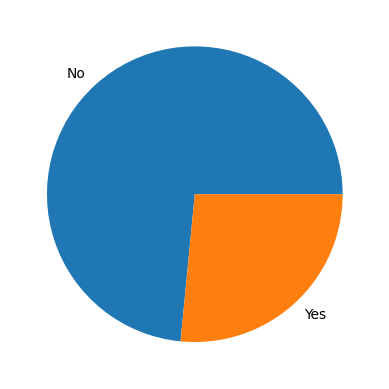

Yes: 26.536987079369588 %
No: 73.4630129206304 %


In [1028]:
df['Churn'].value_counts().plot(kind = 'pie')
plt.show()


yes = df[df['Churn'] == 'Yes'].shape[0]/df.shape[0]*100
no = 100-yes
print('Yes:',yes,'%')
print('No:',no,'%')

In [1029]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692,2279.734304
std,0.368612,24.559481,30.090047,2266.794470
min,0.000000,0.000000,18.250000,0.000000
25%,0.000000,9.000000,35.500000,398.550000
50%,0.000000,29.000000,70.350000,1394.550000
75%,0.000000,55.000000,89.850000,3786.600000
max,1.000000,72.000000,118.750000,8684.800000


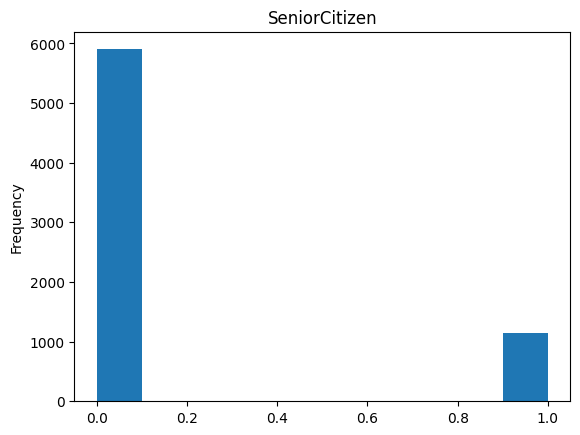

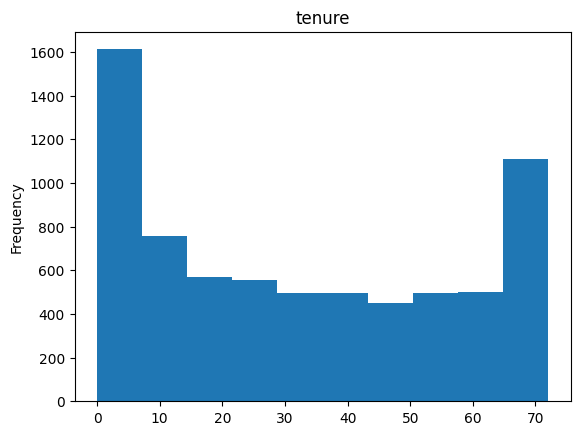

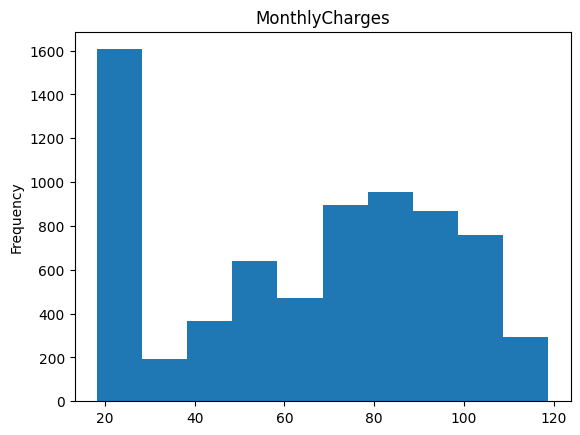

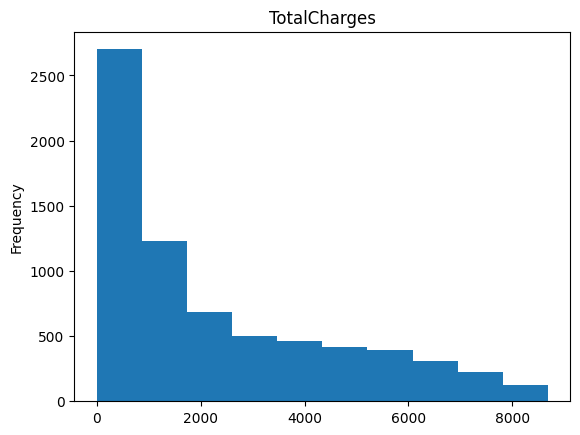

In [1030]:
for x in df.select_dtypes(include='number'):
        df[x].plot(kind='hist')
        plt.title(str(x))
        plt.show()

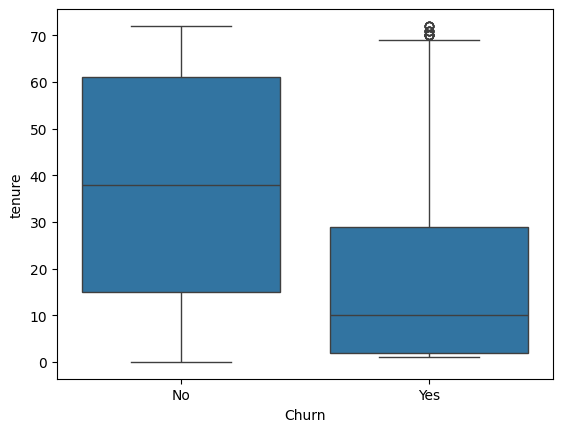

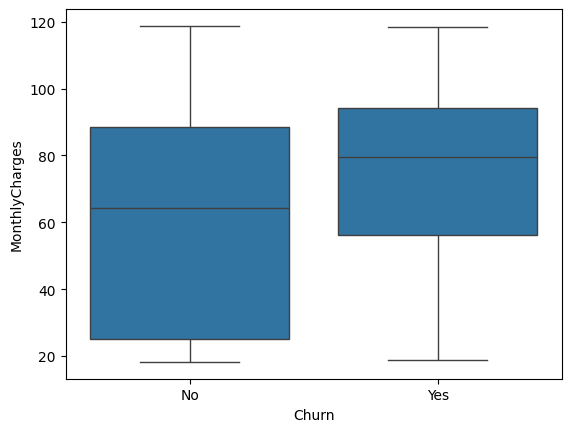

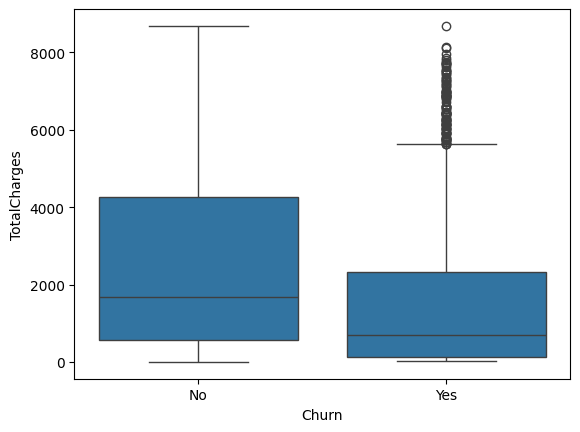

In [1031]:
for z in ['tenure','MonthlyCharges','TotalCharges']:
    sns.boxplot(df,x='Churn',y = z)
    plt.show()

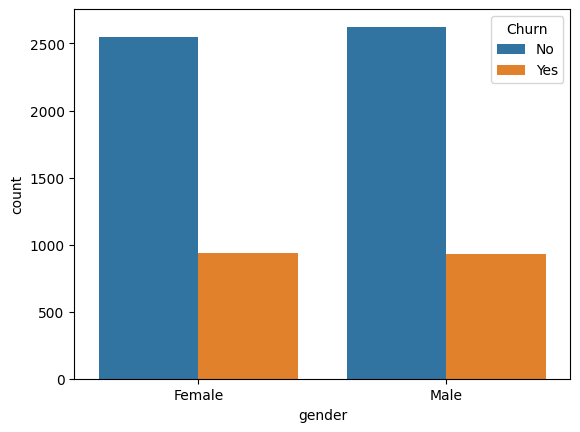

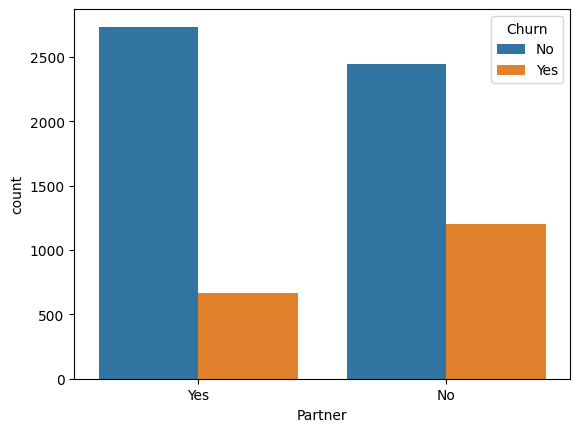

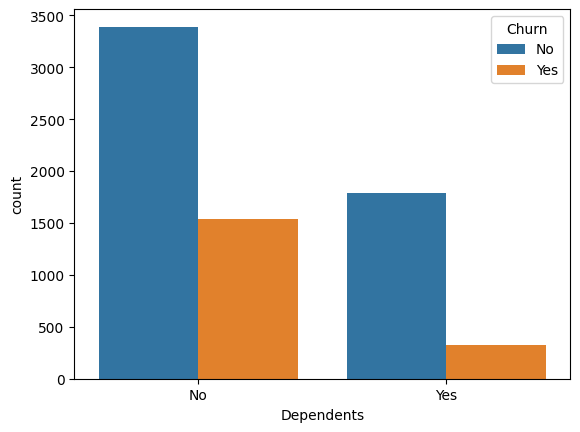

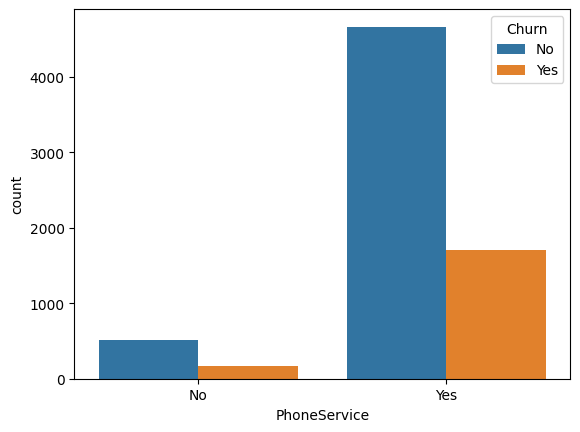

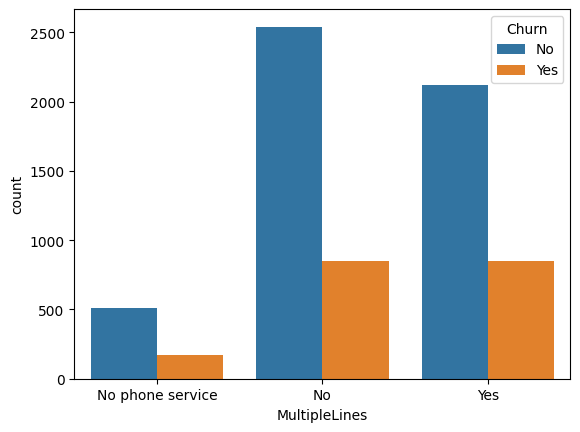

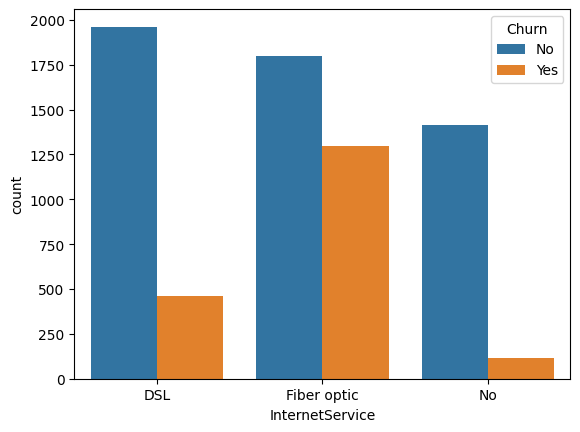

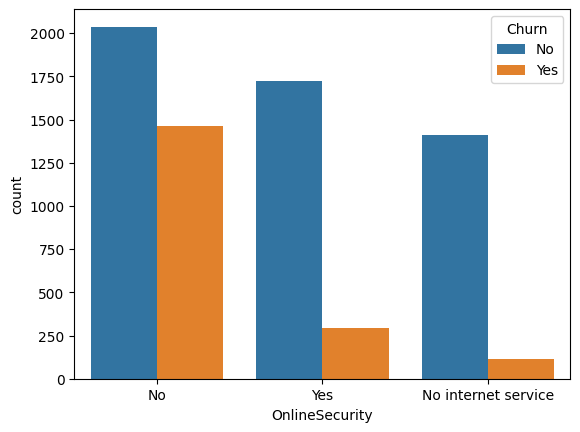

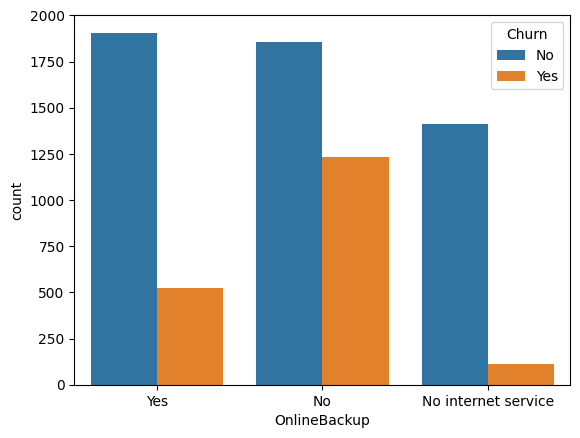

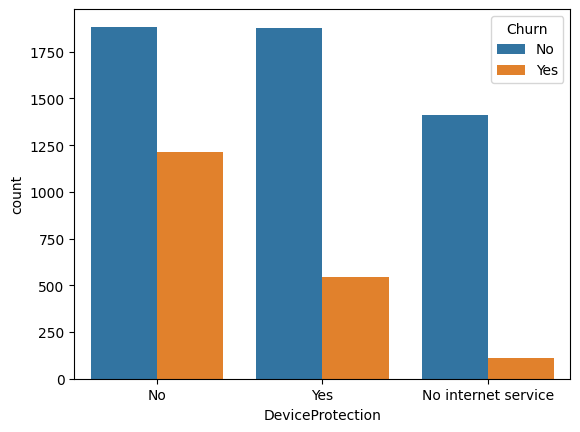

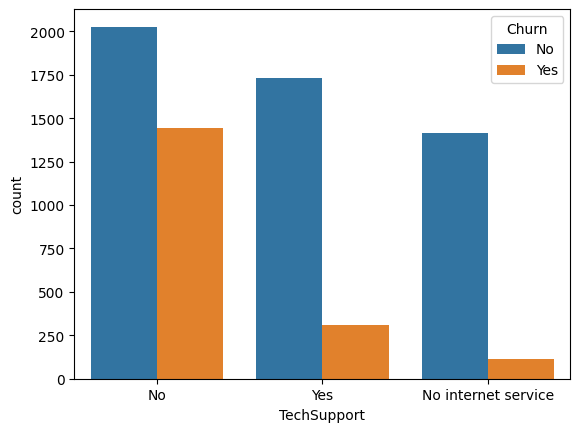

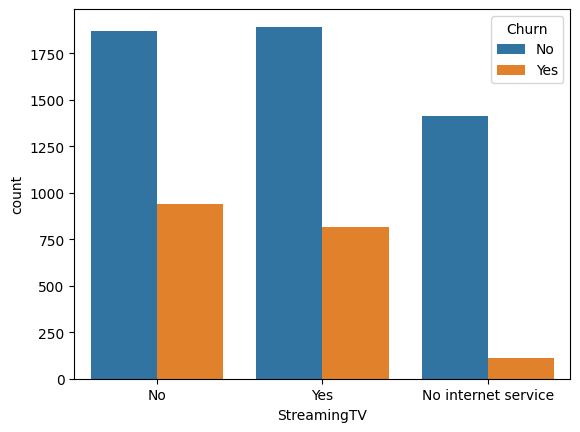

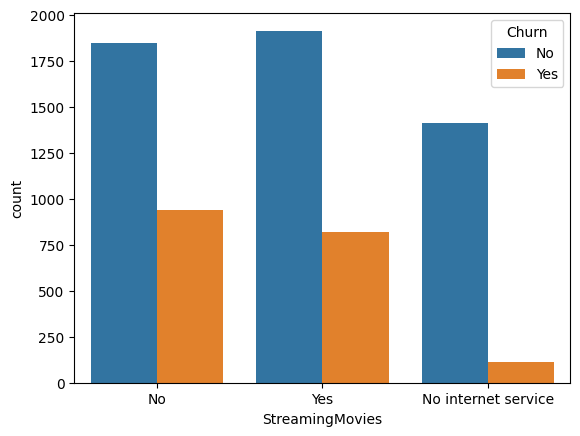

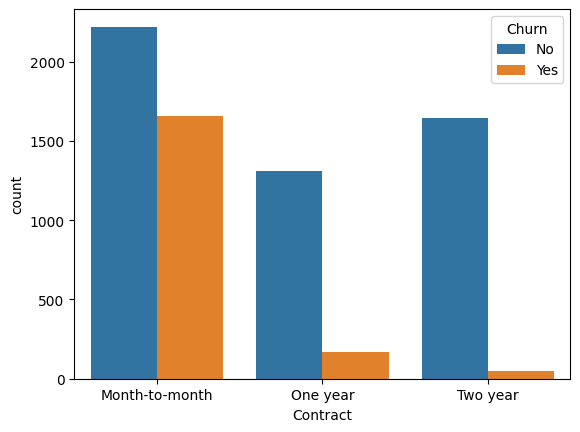

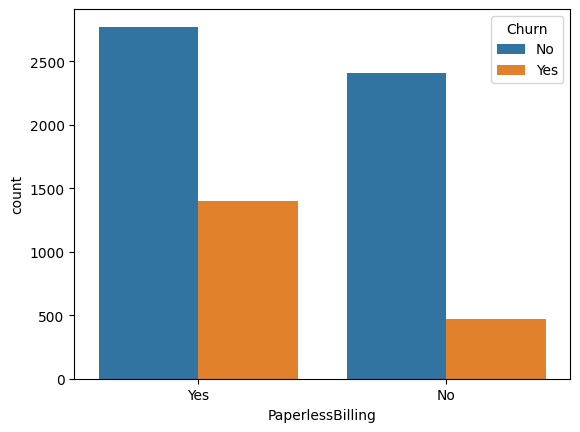

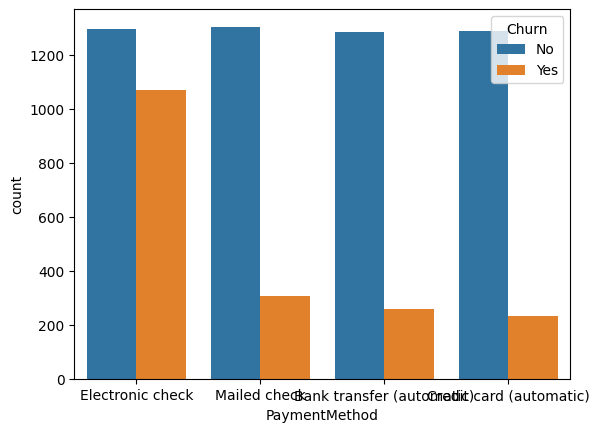

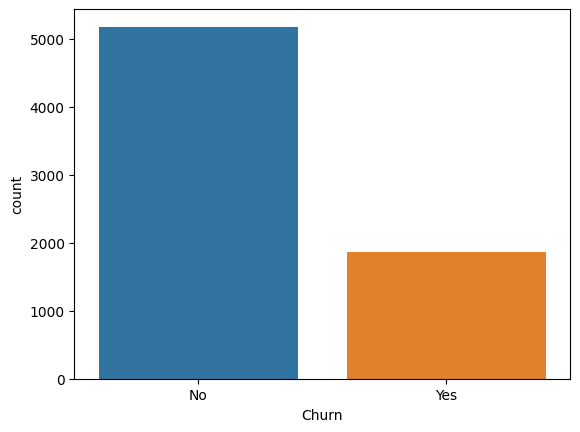

In [1032]:
for z in df.columns:
    if z not in df.select_dtypes(include='number'):
        sns.countplot(df,x = z,hue = 'Churn')
        plt.show()
        

[]

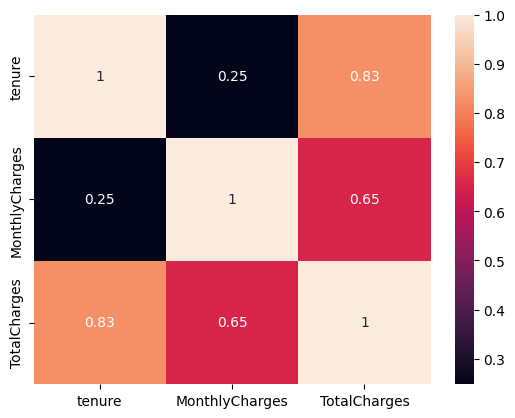

In [1033]:
z = df[['tenure','MonthlyCharges','TotalCharges']].corr()
sns.heatmap(z,annot=True)
plt.plot()

In [1034]:

t = ['Partner', 'Dependents', 'PhoneService', 'PaperlessBilling','gender']
for x in t:
    z = list(set(df[x].values))
    n = len(z)
    df[x] = df[x].map({z[i]:i for i in range(n)})
    
df['Churn'] = df['Churn'].map({'Yes':1,'No':0})


In [1035]:
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,0,0,0,1,1,1,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,0,Electronic check,29.85,29.85,0
1,1,0,1,1,34,0,No,DSL,Yes,No,Yes,No,No,No,One year,1,Mailed check,56.95,1889.50,0
2,1,0,1,1,2,0,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,0,Mailed check,53.85,108.15,1
3,1,0,1,1,45,1,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,1,Bank transfer (automatic),42.30,1840.75,0
4,0,0,1,1,2,0,No,Fiber optic,No,No,No,No,No,No,Month-to-month,0,Electronic check,70.70,151.65,1


In [1036]:
df = pd.get_dummies(df,drop_first = True)

In [1037]:
df.shape

(7043, 31)

In [1038]:
from sklearn.model_selection import train_test_split

In [1039]:
y = df['Churn']
X = df.drop(columns = 'Churn')
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size = 0.2,random_state = 42,stratify=y)

In [1040]:
print(X_train.shape,X_test.shape)

(5634, 30) (1409, 30)


In [1041]:
from sklearn.preprocessing import StandardScaler
l = ['tenure','MonthlyCharges','TotalCharges']

In [1042]:
for x in l:
    ss = StandardScaler()
    X_train[[x]] = ss.fit_transform(X_train[[x]])
    X_test[[x]] = ss.transform(X_test[[x]])

### Logistic Regression

In [1043]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix ,f1_score,classification_report,roc_auc_score,roc_curve,precision_score,recall_score

In [1044]:
lr = LogisticRegression(max_iter = 1000)

In [1045]:
lr.fit(X_train,y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`mul

In [1046]:
y_pred = lr.predict(X_test)
y_proba = lr.predict_proba(X_test)[:,1]

In [1047]:
print(confusion_matrix(y_test,y_pred))
print("f1 score:",f1_score(y_test,y_pred))

[[926 109]
 [165 209]]
f1 score: 0.6040462427745664


In [1048]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1035
           1       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



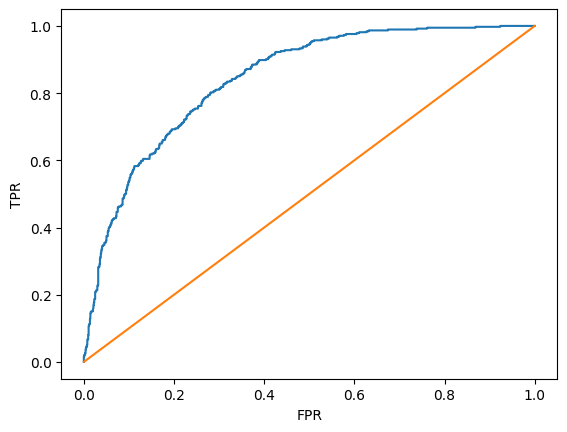

In [1049]:
fpr, tpr, thresholds = roc_curve(y_test, y_proba)
plt.plot(fpr,tpr)
plt.plot([0,1],[0,1])
plt.xlabel('FPR')
plt.ylabel('TPR')

plt.show()

In [1050]:
print(roc_auc_score(y_test,y_proba))

0.8423312407967138


In [1051]:
lr = LogisticRegression(class_weight = 'balanced', max_iter = 1000)

In [1052]:
lr.fit(X_train,y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :ter

In [1053]:
y_pred = lr.predict(X_test)
y_proba = lr.predict_proba(X_test)[:,1]

In [1054]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.90      0.72      0.80      1035
           1       0.51      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409



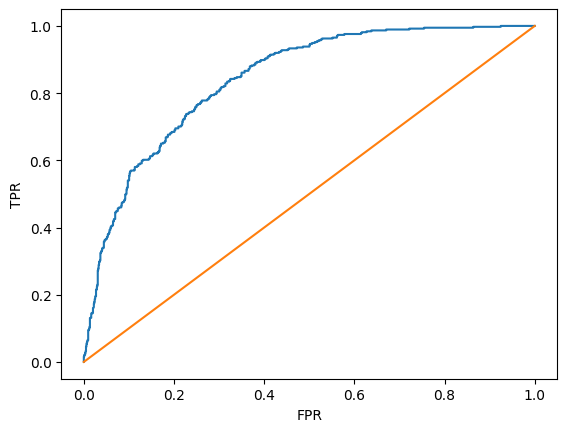

In [1055]:
fpr, tpr, thresholds = roc_curve(y_test, y_proba)
plt.plot(fpr,tpr)
plt.plot([0,1],[0,1])
plt.xlabel('FPR')
plt.ylabel('TPR')

plt.show()

In [1056]:
print(roc_auc_score(y_test,y_proba))

0.841716396703609


In [1057]:
prec = []
recall = []
f1 = []
val = []
t = np.arange(0.2,0.65,0.05)

for x in t:
    y_pred_t = (y_proba>=x).astype(int)
    p = precision_score(y_test,y_pred_t)
    r = recall_score(y_test,y_pred_t)
    f = f1_score(y_test,y_pred_t)
    
    val.append(round(x,2))
    prec.append(round(p,2))
    recall.append(round(r,2))
    f1.append(round(f,2))



result = pd.DataFrame({
    'threshold':val,
    'precision':prec,
    'recall':recall,
    'f1-score':f1
})


print(result)

   threshold  precision  recall  f1-score
0       0.20       0.39    0.96      0.55
1       0.25       0.41    0.94      0.57
2       0.30       0.43    0.93      0.59
3       0.35       0.45    0.90      0.60
4       0.40       0.47    0.87      0.61
5       0.45       0.48    0.84      0.61
6       0.50       0.51    0.78      0.61
7       0.55       0.53    0.75      0.62
8       0.60       0.54    0.71      0.61


### Random Forest

In [1058]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight='balanced',
                            random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)

rf_pred = rf.predict(X_test)
rf_proba = rf.predict_proba(X_test)[:, 1]

print(classification_report(y_test, rf_pred))
print('ROC-AUC:', roc_auc_score(y_test, rf_proba))

              precision    recall  f1-score   support

           0       0.89      0.78      0.83      1035
           1       0.54      0.73      0.62       374

    accuracy                           0.77      1409
   macro avg       0.72      0.75      0.73      1409
weighted avg       0.80      0.77      0.77      1409

ROC-AUC: 0.8428233744090521


### Gradient Boosting

In [1059]:
from sklearn.ensemble import GradientBoostingClassifier

gb = GradientBoostingClassifier(random_state=42)
gb.fit(X_train, y_train)

gb_pred = gb.predict(X_test)
gb_proba = gb.predict_proba(X_test)[:, 1]

print(classification_report(y_test, gb_pred))
print('ROC-AUC:', roc_auc_score(y_test, gb_proba))

              precision    recall  f1-score   support

           0       0.84      0.90      0.87      1035
           1       0.66      0.51      0.57       374

    accuracy                           0.80      1409
   macro avg       0.75      0.71      0.72      1409
weighted avg       0.79      0.80      0.79      1409

ROC-AUC: 0.8415872277764861


### Model Comparison (churn = positive class, threshold 0.5)

In [1060]:
lr_base = LogisticRegression(max_iter=1000).fit(X_train, y_train)
lr_bal = LogisticRegression(class_weight='balanced', max_iter=1000).fit(X_train, y_train)

models = {
    'LR (baseline)': lr_base,
    'LR (balanced)': lr_bal,
    'Random Forest': rf,
    'Gradient Boosting': gb,
}

rows = []
for name, m in models.items():
    proba = m.predict_proba(X_test)[:, 1]
    pred = (proba >= 0.5).astype(int)
    rows.append({
        'model': name,
        'precision': precision_score(y_test, pred),
        'recall': recall_score(y_test, pred),
        'f1': f1_score(y_test, pred),
        'roc_auc': roc_auc_score(y_test, proba),
    })

comparison = pd.DataFrame(rows).set_index('model').round(3)
comparison

,precision,recall,f1,roc_auc
model,,,,
LR (baseline),0.657,0.559,0.604,0.842
LR (balanced),0.505,0.783,0.614,0.842
Random Forest,0.543,0.730,0.623,0.843
Gradient Boosting,0.655,0.508,0.572,0.842


### Hyperparameter Tuning (Gradient Boosting)

In [1061]:
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

param_dist = {
    'n_estimators': [100, 200, 300],
    'learning_rate': [0.02, 0.05, 0.1],
    'max_depth': [2, 3, 4],
    'subsample': [0.7, 0.85, 1.0],
    'min_samples_leaf': [5, 10, 20],
}

search = RandomizedSearchCV(GradientBoostingClassifier(random_state=42), param_dist,
                            n_iter=20, scoring='roc_auc', cv=cv, random_state=42, n_jobs=1)
search.fit(X_train, y_train)

best_gb = search.best_estimator_
print('Best params:', search.best_params_)
print('CV ROC-AUC:', round(search.best_score_, 4))
print('Test ROC-AUC:', round(roc_auc_score(y_test, best_gb.predict_proba(X_test)[:, 1]), 4))

Best params: {'subsample': 0.85, 'n_estimators': 100, 'min_samples_leaf': 20, 'max_depth': 3, 'learning_rate': 0.05}
CV ROC-AUC: 0.8494
Test ROC-AUC: 0.8457


### Threshold Selection for the Final Model

In [1062]:
from sklearn.model_selection import cross_val_predict

oof_proba = cross_val_predict(best_gb, X_train, y_train, cv=cv, method='predict_proba')[:, 1]

thresholds_grid = np.arange(0.1, 0.7, 0.01)
oof_f1 = [f1_score(y_train, (oof_proba >= t).astype(int)) for t in thresholds_grid]
best_t = round(float(thresholds_grid[int(np.argmax(oof_f1))]), 2)
print('Best threshold (max F1 on out-of-fold train predictions):', best_t)

test_proba = best_gb.predict_proba(X_test)[:, 1]
test_pred = (test_proba >= best_t).astype(int)

print(confusion_matrix(y_test, test_pred))
print(classification_report(y_test, test_pred))
print('ROC-AUC:', roc_auc_score(y_test, test_proba))

Best threshold (max F1 on out-of-fold train predictions): 0.33
[[808 227]
 [107 267]]
              precision    recall  f1-score   support

           0       0.88      0.78      0.83      1035
           1       0.54      0.71      0.62       374

    accuracy                           0.76      1409
   macro avg       0.71      0.75      0.72      1409
weighted avg       0.79      0.76      0.77      1409

ROC-AUC: 0.8457477589191144


### Feature Importance

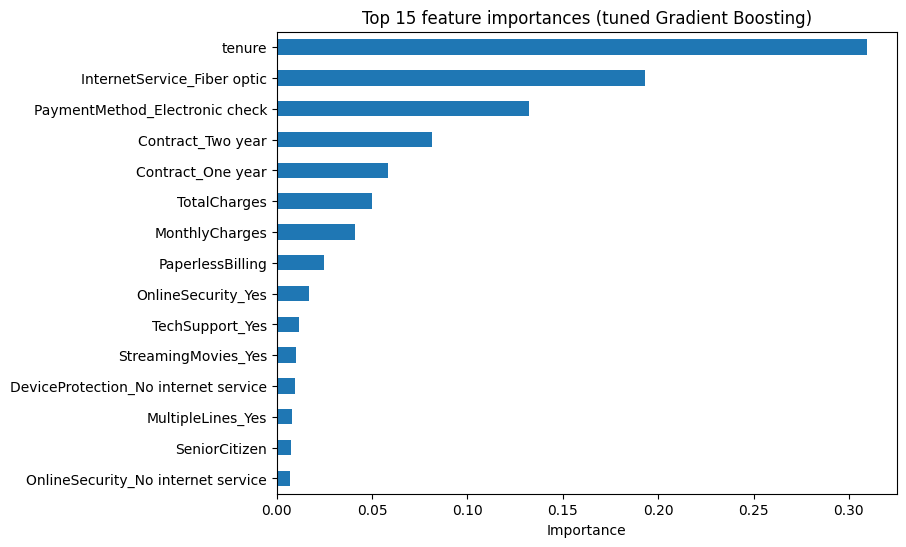

In [1063]:
imp = pd.Series(best_gb.feature_importances_, index=X_train.columns).sort_values(ascending=False).head(15)

imp[::-1].plot(kind='barh', figsize=(8, 6))
plt.title('Top 15 feature importances (tuned Gradient Boosting)')
plt.xlabel('Importance')
plt.show()

### Conclusions

- **Class imbalance:** about 26.5% of customers churn, so accuracy alone is misleading (a model that always predicts "no churn" scores about 73.5%). Models were judged on churn-class precision, recall, F1 and ROC-AUC.
- **Model comparison (threshold 0.5):** all four models reach almost the same ROC-AUC (0.842 to 0.843), so their ability to rank customers by churn risk is nearly identical. They differ mainly in the precision/recall trade-off: baseline logistic regression and default Gradient Boosting are conservative (recall 0.56 and 0.51, precision about 0.66), while balanced logistic regression and Random Forest catch more churners (recall 0.78 and 0.73) at lower precision (0.51 and 0.54). Random Forest has the best F1 at 0.62.
- **Tuned Gradient Boosting:** cross-validated ROC-AUC 0.849 and test ROC-AUC 0.846, a small gain over the other models. The decision threshold of 0.33 was chosen on out-of-fold training predictions, not on the test set.
- **Final result on the test set:** the tuned model at threshold 0.33 catches 267 of 374 churners (recall 0.71) with precision 0.54, at the cost of 227 false alarms among 1035 loyal customers.
- **Most important features:** `tenure` (about 0.31) is the strongest, followed by fiber-optic internet (0.19), electronic-check payment (0.13), and contract type (two-year 0.08, one-year 0.06). `TotalCharges`, `MonthlyCharges` and `PaperlessBilling` follow. Importance shows which features the model relies on, not the direction of the effect; the EDA plots show the direction.
- **Choosing a threshold in practice:** a lower cutoff catches more churners but sends more retention offers to customers who would have stayed. The right value depends on the cost of an offer versus the value of a retained customer.